# Module project: benchmark how networks learn

This notebook builds the whole project, file by file, exactly as the lesson does. Run it from top to bottom in Google Colab or Jupyter: each `%%writefile` cell writes one file of the project, and each `!python` cell runs it. Then try the ideas under **Make it yours**.

Better still: type the files yourself in your own editor, and use this notebook to check your work.

## Attachments and data

- **Notebook**: `project-3-optimizer-benchmark.ipynb`, attached to this lesson. It builds and runs the whole project; on the course's web page it opens in Google Colab.
- **Finished code**: the `projects/optimizer-benchmark` folder in the course files, to check your work.
- **Data**: Fashion-MNIST (Zalando Research). Source: [https://github.com/zalandoresearch/fashion-mnist/tree/master/data/fashion](https://github.com/zalandoresearch/fashion-mnist/tree/master/data/fashion) · about: [https://github.com/zalandoresearch/fashion-mnist](https://github.com/zalandoresearch/fashion-mnist) · licence: MIT. `data.py` downloads it the first time you run it and keeps it in `data/`: `t10k-images-idx3-ubyte.gz`, `t10k-labels-idx1-ubyte.gz`, `train-images-idx3-ubyte.gz`, `train-labels-idx1-ubyte.gz`, 29.4 MB.
- **All datasets in one zip**: [bishop-datasets.zip](https://github.com/mahmoudyosrimahmoud13/inpace-library/releases/download/bishop-datasets-v1/bishop-datasets.zip). Unzip it and copy the files of `fashion-mnist` into your project's `data/` folder; `data.py` then skips the download. Useful offline, or if a source moves.

In [ ]:
%pip install -q torch matplotlib

Chapter 7 is full of choices: plain gradient descent or momentum, RMSProp or Adam, a fixed step or a schedule, how to
initialize the weights, whether to normalize. Reading about them is one thing; in practice, the way to choose is to run
a **fair benchmark**. In this project you build a small benchmarking tool and use it to measure eight training setups
on the same network, with the same data and the same budget.

Knowing how to run a fair comparison and present it clearly is one of the most useful skills in machine learning work.
The notebook attached above builds and runs the whole project; the reference code is in the course files under
`projects/optimizer-benchmark`.

## What you'll build

```mermaid
flowchart LR
    A[experiment.py<br/>one run = one config dict] --> B[benchmark.py<br/>8 configs, same budget,<br/>save results.json]
    B --> C[plot.py<br/>learning curves]
    B --> D[README<br/>results table]
```

Separating "run" from "plot" is deliberate: training takes minutes, redrawing a chart takes a second. Real experiment
code always saves raw results first.

## Set up the project

```bash
mkdir optimizer-benchmark && cd optimizer-benchmark
python -m venv .venv && source .venv/bin/activate
pip install torch matplotlib
git init
```

Copy `data.py` from your clothes classifier (part 1).

```text
optimizer-benchmark/
    .gitignore
    README.md
    benchmark.py
    data.py
    experiment.py
    plot.py
    requirements.txt
```

In [2]:
%%writefile requirements.txt
torch
matplotlib

Writing requirements.txt


In [3]:
%%writefile .gitignore
data/
outputs/
__pycache__/
*.pt
*.json
.venv/

Writing .gitignore


In [4]:
%%writefile data.py
"""Fashion-MNIST: 70,000 grey 28x28 photos of clothes in 10 classes (Zalando Research)."""
from pathlib import Path
from urllib.request import urlopen
import gzip
import torch

URL = "https://raw.githubusercontent.com/zalandoresearch/fashion-mnist/master/data/fashion/"
CLASSES = ["T-shirt", "trouser", "pullover", "dress", "coat", "sandal", "shirt", "sneaker", "bag", "ankle boot"]


def _read(name, offset):
    path = Path("data") / name
    if not path.exists():
        path.parent.mkdir(exist_ok=True)
        path.write_bytes(urlopen(URL + name).read())
    raw = gzip.decompress(path.read_bytes())
    return torch.frombuffer(bytearray(raw[offset:]), dtype=torch.uint8)


def load(split):
    """split: 'train' (60,000 images) or 't10k' (10,000). Returns images as (N, 784) floats in [0, 1] and labels."""
    x = _read(f"{split}-images-idx3-ubyte.gz", 16).reshape(-1, 784).float() / 255
    t = _read(f"{split}-labels-idx1-ubyte.gz", 8).long()
    return x, t


def load_splits():
    x, t = load("train")
    g = torch.Generator().manual_seed(0)
    order = torch.randperm(len(x), generator=g)
    val, train = order[:10000], order[10000:]
    return (x[train], t[train]), (x[val], t[val]), load("t10k")


if __name__ == "__main__":
    (xtr, ttr), (xva, tva), (xte, tte) = load_splits()
    print(f"train {len(xtr)}, validation {len(xva)}, test {len(xte)} images of {xtr.shape[1]} pixels")
    print("images per class in training:", torch.bincount(ttr).tolist())

Writing data.py


## Step 1: one run, described by a config

Every experiment is a small dictionary: which optimizer, which learning rate, whether to use a schedule, batch
normalization or a special initialization. `run` builds the network, trains it for 5 epochs, records the training loss
every 50 steps, and returns the curve and the validation accuracy. Everything else stays fixed, including the random
seed, so the only thing that changes between runs is what the config says.

The network has three hidden layers of 256 ReLU units, deep enough for the choices to matter.

In [5]:
%%writefile experiment.py
"""One training run, fully described by a config dict, returning its learning curve."""
import torch
import torch.nn.functional as F
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
from data import load_splits

(XTR, TTR), (XVA, TVA), _ = load_splits()


def network(batch_norm=False, init_std=None):
    layers, width = [], 784
    for h in [256, 256, 256]:
        layers.append(nn.Linear(width, h))
        if batch_norm:
            layers.append(nn.BatchNorm1d(h))                 # section 7.4.2
        layers.append(nn.ReLU())
        width = h
    layers.append(nn.Linear(width, 10))
    net = nn.Sequential(*layers)
    if init_std is not None:                                 # a deliberately chosen (bad) initialization
        for m in net:
            if isinstance(m, nn.Linear):
                nn.init.normal_(m.weight, std=init_std); nn.init.zeros_(m.bias)
    return net


OPTIMIZERS = {
    "sgd": lambda p, lr: torch.optim.SGD(p, lr=lr),
    "momentum": lambda p, lr: torch.optim.SGD(p, lr=lr, momentum=0.9),
    "rmsprop": lambda p, lr: torch.optim.RMSprop(p, lr=lr),
    "adam": lambda p, lr: torch.optim.Adam(p, lr=lr),
}


def run(cfg, epochs=5, seed=0):
    """cfg: {"opt": "adam", "lr": 1e-3, "schedule": "cosine" or None, "batch_norm": bool, "init_std": float or None}"""
    torch.manual_seed(seed)
    net = network(cfg.get("batch_norm", False), cfg.get("init_std"))
    opt = OPTIMIZERS[cfg["opt"]](net.parameters(), cfg["lr"])
    loader = DataLoader(TensorDataset(XTR, TTR), batch_size=128, shuffle=True)
    steps = epochs * len(loader)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, steps) if cfg.get("schedule") == "cosine" else None
    curve, step = [], 0
    for epoch in range(epochs):
        net.train()
        for x, t in loader:
            loss = F.cross_entropy(net(x), t)
            opt.zero_grad(); loss.backward(); opt.step()
            if sched:
                sched.step()
            step += 1
            if step % 50 == 0:
                curve.append((step, loss.item()))
    net.eval()
    with torch.no_grad():
        val_acc = (net(XVA).argmax(1) == TVA).float().mean().item()
    return {"curve": curve, "val_acc": val_acc, "final_loss": sum(l for _, l in curve[-10:]) / 10}

Writing experiment.py


## Step 2: run the benchmark

In [6]:
%%writefile benchmark.py
"""Compare optimizers, schedules, initialization and normalization on the same network and budget (5 epochs)."""
import json
from pathlib import Path
from experiment import run

EXPERIMENTS = {
    "SGD, lr 0.01": {"opt": "sgd", "lr": 0.01},
    "SGD + momentum 0.9, lr 0.01": {"opt": "momentum", "lr": 0.01},
    "RMSProp, lr 0.001": {"opt": "rmsprop", "lr": 1e-3},
    "Adam, lr 0.001": {"opt": "adam", "lr": 1e-3},
    "Adam, lr 0.001, cosine schedule": {"opt": "adam", "lr": 1e-3, "schedule": "cosine"},
    "Adam, lr 0.01 (too big)": {"opt": "adam", "lr": 1e-2},
    "Adam, weights init std 1.0 (bad)": {"opt": "adam", "lr": 1e-3, "init_std": 1.0},
    "Adam, init std 1.0 + batch norm": {"opt": "adam", "lr": 1e-3, "init_std": 1.0, "batch_norm": True},
}
results = {}
print(f"{'experiment':36s} {'final train loss':>16s} {'val accuracy':>13s}")
for name, cfg in EXPERIMENTS.items():
    r = run(cfg)
    results[name] = r
    print(f"{name:36s} {r['final_loss']:16.3f} {r['val_acc']:13.3f}")

Path("outputs").mkdir(exist_ok=True)
Path("outputs/results.json").write_text(json.dumps(results))
print("saved outputs/results.json")

Writing benchmark.py


In [7]:
!python benchmark.py

experiment                           final train loss  val accuracy


SGD, lr 0.01                                    0.749         0.741


SGD + momentum 0.9, lr 0.01                     0.409         0.857


RMSProp, lr 0.001                               0.337         0.860


Adam, lr 0.001                                  0.343         0.874


Adam, lr 0.001, cosine schedule                 0.317         0.878


Adam, lr 0.01 (too big)                         0.401         0.853


Adam, weights init std 1.0 (bad)              242.767         0.804


Adam, init std 1.0 + batch norm                 0.347         0.839
saved outputs/results.json


In [8]:
%%writefile plot.py
"""Draw the learning curves saved by benchmark.py."""
import json
from pathlib import Path
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt

results = json.loads(Path("outputs/results.json").read_text())
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
for i, (name, r) in enumerate(results.items()):
    ax = axes[0] if i < 5 else axes[1]
    steps, losses = zip(*r["curve"])
    smooth = [sum(losses[max(0, j - 4):j + 1]) / len(losses[max(0, j - 4):j + 1]) for j in range(len(losses))]
    ax.plot(steps, smooth, label=name)
for ax, title in zip(axes, ["optimizers and schedules", "step size, initialization, batch norm"]):
    ax.set_yscale("log"); ax.set_xlabel("training step"); ax.set_title(title); ax.legend(fontsize=8)
axes[0].set_ylim(0.2, 3)
axes[0].set_ylabel("training loss (smoothed, log scale)")
fig.tight_layout(); fig.savefig("outputs/curves.png", dpi=110)
print("saved outputs/curves.png")

Writing plot.py


In [9]:
!python plot.py

saved outputs/curves.png


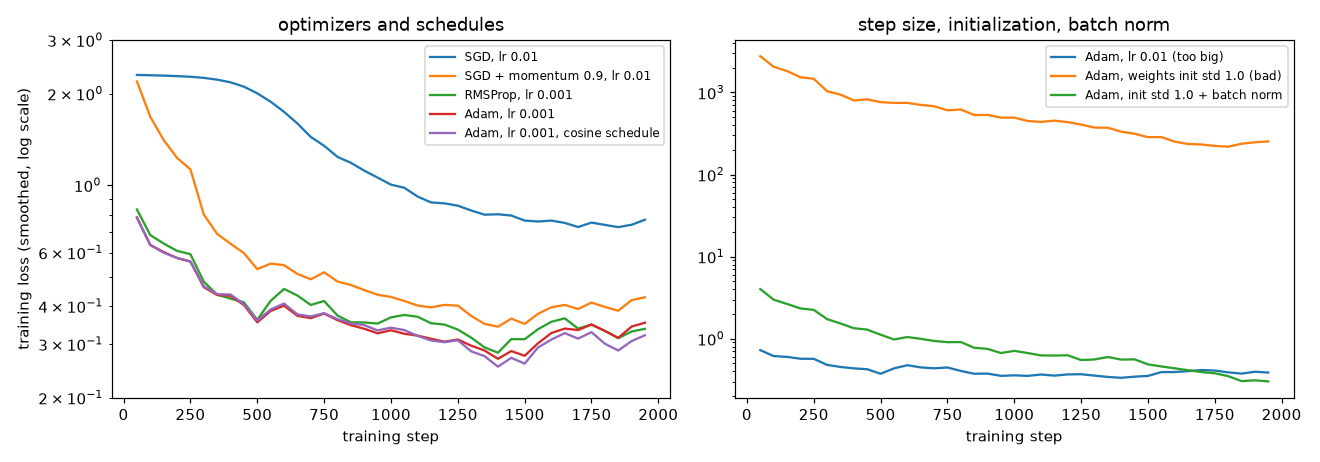

In [10]:
from IPython.display import Image
Image('outputs/curves.png')

Read it one comparison at a time, each matching a section of the chapter:

- **SGD against momentum** (section 7.3.1): with the same learning rate, adding momentum cuts the final loss from 0.75
  to 0.41 and lifts accuracy from 0.74 to 0.86. Plain SGD spends its first 300 steps barely moving: the loss surface is
  a narrow valley, and momentum builds up speed along it.
- **RMSProp and Adam** (section 7.3.3): adaptive step sizes per parameter. Both beat momentum, Adam slightly ahead.
- **A schedule** (section 7.3.2): the same Adam, with the learning rate decaying along a cosine curve, gets the best
  result of all. Big steps early to make progress, small steps late to settle.
- **A step that's too big**: Adam with 0.01 instead of 0.001 learns fast at first, then stalls and gets worse.
- **Initialization** (section 7.2.5): weights drawn with standard deviation 1.0, instead of PyTorch's default (uniform
  between ±1/√784 for the first layer, a standard deviation of about 0.02). Each layer multiplies the scale of its inputs by roughly √256 = 16, so after three
  layers the outputs are thousands of times too large. The loss starts at about 2,800 and is still around 240 after
  5 epochs. Strangely, accuracy is still 0.80: the network often points at the right class, but with absurd confidence.
  That's why you should always look at the loss, not only the accuracy.
- **Batch normalization** (section 7.4.2) rescales each layer's activations using the mini-batch's mean and variance.
  With the same terrible initialization, it brings the loss back to 0.35 (the right-hand panel uses its own scale for
  this reason). It doesn't fully catch up with a well-initialized network in 5 epochs, but it turns a broken run into a
  working one.

And the limits of this benchmark, which belong in your README: one seed, one network, one data set, five epochs. A
difference of 0.004 in accuracy (Adam with and without a schedule) could be noise. The **Make it yours** ideas fix that.

## Step 3: write the README and publish

In [11]:
%%writefile README.md
# Optimizer benchmark

A controlled benchmark of how neural networks are trained: the same 3-hidden-layer network on Fashion-MNIST, the same
5-epoch budget, and eight training setups (optimizers, learning-rate schedules, initialization, batch normalization),
in PyTorch.

![curves](outputs/curves.png)

## Results

| setup | final training loss | validation accuracy |
|---|---|---|
| SGD, lr 0.01 | 0.749 | 0.741 |
| SGD + momentum 0.9 | 0.409 | 0.857 |
| RMSProp, lr 0.001 | 0.337 | 0.860 |
| Adam, lr 0.001 | 0.343 | 0.874 |
| Adam + cosine schedule | **0.317** | **0.878** |
| Adam, lr 0.01 (too big) | 0.401 | 0.853 |
| Adam, weights initialized with std 1.0 | 242.8 | 0.804 |
| same bad initialization + batch norm | 0.347 | 0.839 |

## Run it

```bash
pip install -r requirements.txt
python benchmark.py   # about 3 minutes on a laptop CPU
python plot.py
```

## What I learned

- Plain SGD with a fixed step is slow; momentum alone closes most of the gap to Adam.
- A cosine learning-rate schedule gave the best result for free.
- A bad initialization can make the loss explode by a factor of a thousand; batch normalization rescued it.

Based on chapter 7 of *Deep Learning: Foundations and Concepts* (Bishop & Bishop, 2024).

Writing README.md


```bash
git add .
git commit -m "Optimizer, schedule, initialization and batch norm benchmark"
git branch -M main
git remote add origin git@github.com:YOUR-USERNAME/optimizer-benchmark.git
git push -u origin main
```

## Make it yours

- **Seeds and error bars.** Run each config with 3 seeds and report mean ± standard deviation. Which differences
  survive?
- **A learning-rate finder.** Train for one epoch while raising the learning rate exponentially from 1e-6 to 1, and plot
  the loss against the learning rate. Where does it fall fastest? Does that match the best fixed rate?
- **Weight decay vs AdamW.** Add `torch.optim.AdamW(p, lr, weight_decay=0.01)` and Adam with `weight_decay=0.01`. They
  aren't the same thing. Can you see the difference?
- **Command-line configs.** Let `benchmark.py` read experiments from a JSON or YAML file, so anyone can add a run
  without touching the code.

## On your CV

> **Neural network training benchmark** (PyTorch): controlled comparison of SGD, momentum, RMSProp, Adam, learning-rate
> schedules, weight initialization and batch normalization on a 3-layer MLP; showed a bad initialization raising the
> loss ~700x and batch normalization recovering it. github.com/YOUR-USERNAME/optimizer-benchmark

## Check yourself

- [ ] Every run uses the same seed, network, data and number of epochs.
- [ ] Raw results are saved before plotting.
- [ ] You can explain why accuracy stayed at 0.80 while the loss was 240.
- [ ] Your README says what the benchmark can't tell you.